# Day 3 — Customer Feedback Analysis Using NLP

## Business objective
Use customer reviews to understand sentiment, evaluate a traditional text-classification model, and identify recurring sources of dissatisfaction.

## 1. Import libraries and define project paths

Keep setup in one cell so dependencies and output locations are easy to verify. Run this notebook from the project folder or its `notebooks/` directory.

In [1]:
from pathlib import Path
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.sparse import save_npz
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 100)

# Find the repository root whether this notebook is opened from notebooks/ or the root.
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current, *current.parents] if (path / "data" / "raw").is_dir()),
    current
)
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "day3"
REPORTS_DIR = PROJECT_ROOT / "reports"

for folder in [PROCESSED_DIR, MODEL_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: /home/nineleaps-admin/uber-eats-intelligence


## 2. Load and understand the review data

First inspect the schema, missing values, duplicate rows, and supplied sentiment labels. Repeated review text is expected in this synthetic dataset because many customers can use the same review wording; **do not remove records just because the text repeats**.

In [2]:
reviews_raw = pd.read_csv(RAW_DIR / "reviews.csv")
required_columns = {"review_text", "sentiment_label"}
missing_columns = required_columns - set(reviews_raw.columns)
if missing_columns:
    raise ValueError(f"reviews.csv is missing required columns: {sorted(missing_columns)}")

print("Rows and columns:", reviews_raw.shape)
print("Unique review texts:", reviews_raw["review_text"].nunique())
display(reviews_raw.head())
display(reviews_raw.isna().sum().rename("missing_values").to_frame())
display(reviews_raw["sentiment_label"].value_counts().rename_axis("sentiment").to_frame("review_count"))

Rows and columns: (5968, 8)
Unique review texts: 16


,review_id,order_id,customer_id,restaurant_id,review_text,rating,sentiment_label,review_timestamp
0,700001,100001,1891,74,"Order was fine, but could be better",3,Neutral,2025-11-17 19:14:00
1,700002,100002,1669,20,Food arrived late and was not fresh,1,Negative,2025-11-14 19:39:00
2,700003,100003,107,54,Delivery was late and the food was cold,3,Negative,2025-01-05 15:42:00
3,700004,100005,800,20,Incorrect order and disappointing service,1,Negative,2025-12-28 23:57:00
4,700005,100008,12,2,"Loved the meal, would order again",5,Positive,2025-07-02 03:10:00


,missing_values
review_id,0
order_id,0
customer_id,0
restaurant_id,0
review_text,0
rating,0
sentiment_label,0
review_timestamp,0


,review_count
sentiment,
Positive,3426
Neutral,1360
Negative,1182


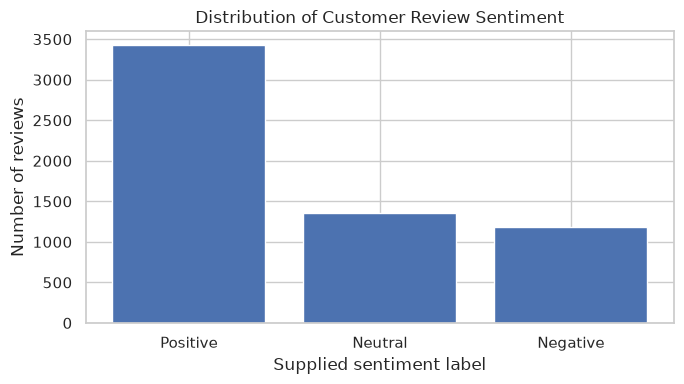

In [3]:
# Plot the supplied sentiment-label distribution.
plt.figure(figsize=(7, 4))
sentiment_counts = reviews_raw["sentiment_label"].value_counts()
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribution of Customer Review Sentiment")
plt.xlabel("Supplied sentiment label")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## 3. Clean and preprocess review text

Traditional bag-of-words models benefit from consistent text. This pipeline lowercases text, removes URLs and punctuation, tokenizes words, removes common stop words, and lemmatizes words where possible. Negation words such as **not**, **no**, and **never** are deliberately retained because they can reverse meaning.

The notebook uses NLTK's WordNet lemmatizer. If the WordNet resource is not available, it attempts to download it. If download access is unavailable, the pipeline falls back to a simple conservative suffix normalizer and clearly reports that fallback.

In [4]:
import nltk
from nltk.stem import WordNetLemmatizer

# Use a stop-word list that retains negation words.
negation_words = {"no", "nor", "not", "never", "n't"}
stop_words = set(ENGLISH_STOP_WORDS) - negation_words
lemmatizer = WordNetLemmatizer()

try:
    nltk.data.find("corpora/wordnet")
    LEMMATIZATION_MODE = "WordNet lemmatization"
except LookupError:
    try:
        nltk.download("wordnet", quiet=True)
        nltk.data.find("corpora/wordnet")
        LEMMATIZATION_MODE = "WordNet lemmatization"
    except Exception:
        LEMMATIZATION_MODE = "simple suffix fallback"

print("Text normalization:", LEMMATIZATION_MODE)

Text normalization: simple suffix fallback


In [23]:
def clean_review_text(text):
    """Normalize a review into tokens for traditional ML text features."""
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    cleaned_tokens = []
    for token in tokens:
        # Remove stop words but preserve negation terms.
        if token in stop_words:
            continue

        if LEMMATIZATION_MODE == "WordNet lemmatization":
            token = lemmatizer.lemmatize(token)
        else:
            # Small fallback only; WordNet is preferred for proper lemmatization.
            if token.endswith("ies") and len(token) > 4:
                token = token[:-3] + "y"
            elif token.endswith("s") and not token.endswith("ss") and len(token) > 3:
                token = token[:-1]

        cleaned_tokens.append(token)

    return " ".join(cleaned_tokens)

# Quick examples to demonstrate the cleaning function.
examples = pd.DataFrame({
    "original": ["The food was NOT fresh!!!", "Loved the delicious meal :)"],
})
examples["cleaned"] = examples["original"].apply(clean_review_text)
display(examples)

,original,cleaned
0,The food was NOT fresh!!!,food not fresh
1,Loved the delicious meal :),loved deliciou meal


In [6]:
# Remove rows with missing review text or labels, but preserve repeated reviews.
reviews = reviews_raw.dropna(subset=["review_text", "sentiment_label"]).copy()
reviews["review_text"] = reviews["review_text"].astype(str).str.strip()
reviews["cleaned_review"] = reviews["review_text"].apply(clean_review_text)
reviews = reviews[reviews["cleaned_review"].str.len() > 0].copy()
reviews["sentiment_label"] = reviews["sentiment_label"].astype(str).str.strip().str.title()
reviews = reviews.reset_index(drop=True)

cleaned_path = PROCESSED_DIR / "reviews_cleaned.csv"
reviews.to_csv(cleaned_path, index=False)

print("Usable review records:", len(reviews))
print("Repeated text records retained:", len(reviews) - reviews["review_text"].nunique())
print("Saved cleaned dataset:", cleaned_path)
display(reviews[["review_text", "cleaned_review", "sentiment_label"]].head(10))

Usable review records: 5968
Repeated text records retained: 5952
Saved cleaned dataset: /home/nineleaps-admin/uber-eats-intelligence/data/processed/reviews_cleaned.csv


,review_text,cleaned_review,sentiment_label
0,"Order was fine, but could be better",order fine better,Neutral
1,Food arrived late and was not fresh,food arrived late not fresh,Negative
2,Delivery was late and the food was cold,delivery late food cold,Negative
3,Incorrect order and disappointing service,incorrect order disappointing service,Negative
4,"Loved the meal, would order again",loved meal order,Positive
5,The food was okay and delivery was average,food okay delivery average,Neutral
6,The food was okay and delivery was average,food okay delivery average,Neutral
7,Delicious food and good value,deliciou food good value,Positive
8,"Fresh and tasty, arrived on time",fresh tasty arrived time,Positive
9,The food was okay and delivery was average,food okay delivery average,Neutral


## 4. Create a train/test split

The target is the sentiment label supplied by the synthetic data generator. We hold out 20% of records for evaluation and stratify the split so each sentiment class is represented in both sets. Repeated template wording means the evaluation measures performance on held-out records, not necessarily on completely new writing styles.

In [7]:
X = reviews["cleaned_review"]
y = reviews["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training records: {len(X_train):,}")
print(f"Test records: {len(X_test):,}")
print("Classes:", sorted(y.unique()))

Training records: 4,774
Test records: 1,194
Classes: ['Negative', 'Neutral', 'Positive']


## 5. Convert text into TF-IDF features and train Naive Bayes

TF-IDF gives more weight to terms that are informative within a document and less weight to terms that appear in almost every document. The vectorizer is inside a scikit-learn pipeline, so it learns its vocabulary from the training split only. We use unigram and bigram features to capture both single words and short phrases.

In [8]:
sentiment_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB(alpha=0.5))
])

sentiment_pipeline.fit(X_train, y_train)
y_pred = sentiment_pipeline.predict(X_test)
print("Naive Bayes model trained and predictions generated.")

Naive Bayes model trained and predictions generated.


In [9]:
# Save the sparse TF-IDF matrix for all cleaned records using the training-fitted vocabulary.
tfidf = sentiment_pipeline.named_steps["tfidf"]
tfidf_matrix = tfidf.transform(reviews["cleaned_review"])

matrix_path = PROCESSED_DIR / "reviews_tfidf_matrix.npz"
save_npz(matrix_path, tfidf_matrix)

vocabulary_path = PROCESSED_DIR / "reviews_tfidf_vocabulary.csv"
pd.DataFrame({
    "feature_index": np.arange(len(tfidf.get_feature_names_out())),
    "term_or_phrase": tfidf.get_feature_names_out()
}).to_csv(vocabulary_path, index=False)

# A small human-readable preview; the full matrix stays sparse to save disk space.
preview_columns = min(12, tfidf_matrix.shape[1])
preview = pd.DataFrame(
    tfidf_matrix[:8, :preview_columns].toarray(),
    columns=tfidf.get_feature_names_out()[:preview_columns]
)
preview_path = PROCESSED_DIR / "reviews_tfidf_preview.csv"
preview.to_csv(preview_path, index=False)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Saved matrix:", matrix_path)
print("Saved vocabulary and preview.")
display(preview)

TF-IDF matrix shape: (5968, 84)
Saved matrix: /home/nineleaps-admin/uber-eats-intelligence/data/processed/reviews_tfidf_matrix.npz
Saved vocabulary and preview.


,acceptable,arrived,arrived late,arrived time,average,average experience,better,cold,cold disappointing,communication,deliciou,deliciou food
0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.4712,0.000000,0.0,0.0,0.000000,0.000000
1,0.0,0.263168,0.382328,0.0,0.000000,0.0,0.0000,0.000000,0.0,0.0,0.000000,0.000000
2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0000,0.385558,0.0,0.0,0.000000,0.000000
3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0000,0.000000,0.0,0.0,0.000000,0.000000
4,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0000,0.000000,0.0,0.0,0.000000,0.000000
5,0.0,0.000000,0.000000,0.0,0.355842,0.0,0.0000,0.000000,0.0,0.0,0.000000,0.000000
6,0.0,0.000000,0.000000,0.0,0.355842,0.0,0.0000,0.000000,0.0,0.0,0.000000,0.000000
7,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0000,0.000000,0.0,0.0,0.397719,0.397719


## 6. Evaluate the sentiment classifier

Accuracy gives the overall share of correct predictions. Precision, recall, and F1-score show performance for each sentiment class. Since the classes are not equally frequent, inspect the per-class results rather than relying on accuracy alone.

In [10]:
accuracy = accuracy_score(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()

summary_metrics = pd.DataFrame([{
    "test_records": len(y_test),
    "accuracy": accuracy,
    "weighted_precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "weighted_recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "weighted_f1_score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
}])

display(summary_metrics.round(3))
display(report_df.round(3))

,test_records,accuracy,weighted_precision,weighted_recall,weighted_f1_score
0,1194,1.0,1.0,1.0,1.0


,precision,recall,f1-score,support
Negative,1.0,1.0,1.0,237.0
Neutral,1.0,1.0,1.0,272.0
Positive,1.0,1.0,1.0,685.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1194.0
weighted avg,1.0,1.0,1.0,1194.0


In [11]:
report_path = REPORTS_DIR / "sentiment_classification_report.csv"
summary_path = REPORTS_DIR / "sentiment_summary_metrics.csv"
report_df.to_csv(report_path)
summary_metrics.to_csv(summary_path, index=False)
print("Saved:", report_path)
print("Saved:", summary_path)

Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/sentiment_classification_report.csv
Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/sentiment_summary_metrics.csv


## 7. Confusion matrix

Rows are actual labels and columns are predicted labels. Off-diagonal values represent mistakes; this helps identify which sentiment classes the model confuses.

,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,237,0,0
Actual Neutral,0,272,0
Actual Positive,0,0,685


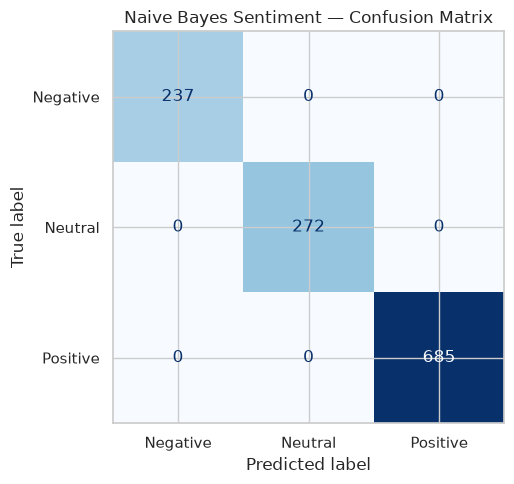

Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/sentiment_confusion_matrix.csv


In [12]:
class_names = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=class_names)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in class_names],
    columns=[f"Predicted {label}" for label in class_names]
)
display(cm_df)
cm_path = REPORTS_DIR / "sentiment_confusion_matrix.csv"
cm_df.to_csv(cm_path)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Naive Bayes Sentiment — Confusion Matrix")
plt.tight_layout()
plt.show()
print("Saved:", cm_path)

## 8. Identify words and phrases associated with sentiment

For each class, compare its learned word probabilities with the average probabilities for the other classes. The resulting association score highlights terms that are relatively distinctive, rather than simply showing the most common words. We also remove generic filler terms from the display. Interpret these as clues, not causal explanations.

In [13]:
classifier = sentiment_pipeline.named_steps["classifier"]
terms = np.array(tfidf.get_feature_names_out())
class_log_probs = classifier.feature_log_prob_
class_labels = classifier.classes_

# Filter generic terms from interpretation only; the model itself keeps its learned vocabulary.
extra_generic = {
    "food", "order", "meal", "restaurant", "delivery", "service",
    "experience", "average", "time", "item", "place", "would", "one"
}
stop_for_display = stop_words | extra_generic

term_rows = []
for class_index, sentiment in enumerate(class_labels):
    other_indices = [i for i in range(len(class_labels)) if i != class_index]
    association = class_log_probs[class_index] - class_log_probs[other_indices].mean(axis=0)

    eligible = np.array([
        bool(re.search(r"[a-z]", term))
        and not all(part in stop_for_display for part in term.split())
        and not any(part in stop_for_display for part in term.split())
        for term in terms
    ])
    candidate_indices = np.where(eligible)[0]
    ranked_indices = candidate_indices[np.argsort(association[candidate_indices])[-10:][::-1]]

    for rank, index in enumerate(ranked_indices, start=1):
        term_rows.append({
            "sentiment": sentiment,
            "rank": rank,
            "term_or_phrase": terms[index],
            "association_score": round(float(association[index]), 4)
        })

top_terms = pd.DataFrame(term_rows)
display(top_terms)

,sentiment,rank,term_or_phrase,association_score
0,Negative,1,cold,6.0319
1,Negative,2,disappointing,5.9902
2,Negative,3,late,5.9173
3,Negative,4,poor,5.8255
4,Negative,5,cold disappointing,5.5415
5,Negative,6,incorrect,5.3914
6,Negative,7,communication,5.3183
7,Negative,8,long,5.3183
8,Negative,9,long preparation,5.3183
9,Negative,10,preparation,5.3183


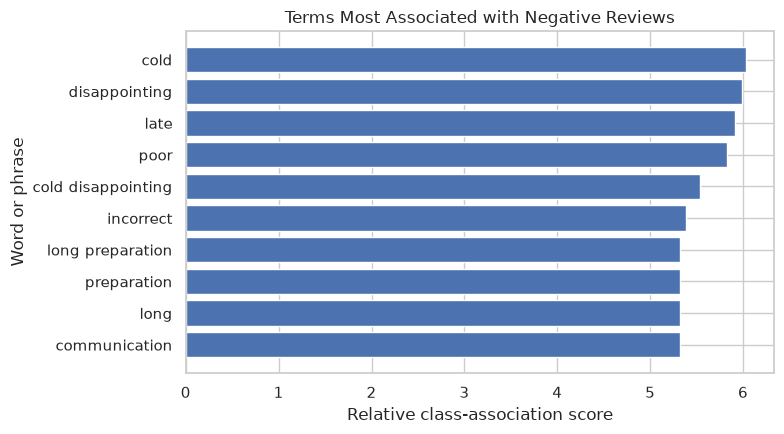

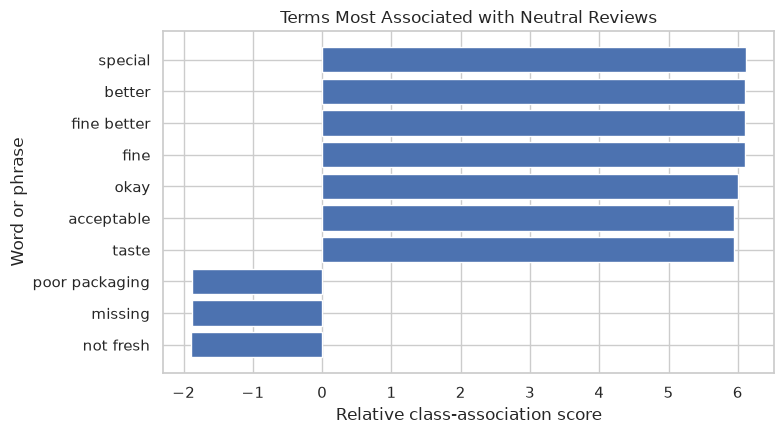

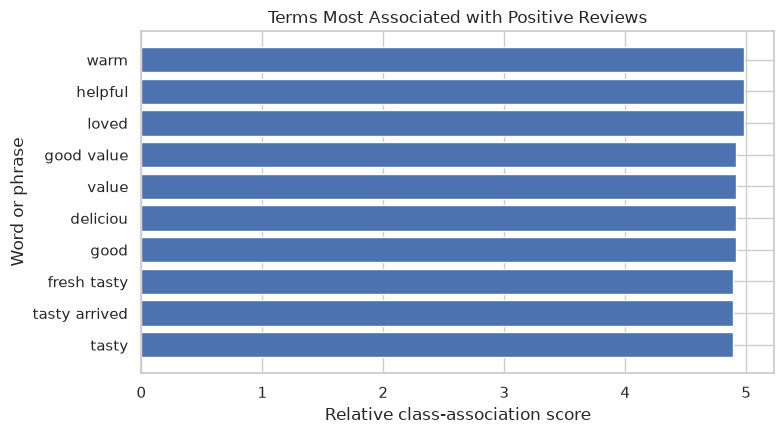

Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/sentiment_top_terms.csv


,term,present_in_model_vocabulary
0,tasty,True
1,loved,True
2,excellent,True
3,delicious,False
4,great,True


In [14]:
# Plot the strongest terms for each class and save the table.
for sentiment in class_labels:
    plot_data = top_terms[top_terms["sentiment"] == sentiment].sort_values("association_score")
    plt.figure(figsize=(8, 4.5))
    plt.barh(plot_data["term_or_phrase"], plot_data["association_score"])
    plt.title(f"Terms Most Associated with {sentiment} Reviews")
    plt.xlabel("Relative class-association score")
    plt.ylabel("Word or phrase")
    plt.tight_layout()
    plt.show()

terms_path = REPORTS_DIR / "sentiment_top_terms.csv"
top_terms.to_csv(terms_path, index=False)
print("Saved:", terms_path)

# Check expected sentiment vocabulary terms without forcing them into the top 10.
positive_terms_to_check = ["tasty", "loved", "excellent", "delicious", "great"]
vocabulary_set = set(terms)
term_check = pd.DataFrame({
    "term": positive_terms_to_check,
    "present_in_model_vocabulary": [term in vocabulary_set for term in positive_terms_to_check]
})
display(term_check)

## 9. Explore common issues in negative reviews

We use two complementary views:
- **Keyword frequency:** how many negative reviews contain a word or phrase.
- **Issue categories:** simple transparent rules for common delivery-app issues such as late delivery, cold food, incorrect orders, and service problems.

These are exploratory categories. Review examples should be checked before treating them as definitive complaint themes.

In [15]:
negative_reviews = reviews[
    reviews["sentiment_label"].str.lower().eq("negative")
].copy()
print("Negative review records:", len(negative_reviews))
display(negative_reviews[["review_text", "cleaned_review"]].head(8))

Negative review records: 1182


,review_text,cleaned_review
1,Food arrived late and was not fresh,food arrived late not fresh
2,Delivery was late and the food was cold,delivery late food cold
3,Incorrect order and disappointing service,incorrect order disappointing service
25,Missing items and poor packaging,missing item poor packaging
29,Long preparation time and poor communication,long preparation time poor communication
35,The meal was cold and disappointing,meal cold disappointing
38,Missing items and poor packaging,missing item poor packaging
39,Incorrect order and disappointing service,incorrect order disappointing service


In [16]:
# Count how many negative reviews contain each term or phrase.
complaint_vectorizer = CountVectorizer(
    stop_words=list(stop_for_display),
    ngram_range=(1, 2),
    min_df=1,
    binary=True
)
complaint_matrix = complaint_vectorizer.fit_transform(negative_reviews["cleaned_review"])
complaint_terms = complaint_vectorizer.get_feature_names_out()
review_counts = np.asarray(complaint_matrix.sum(axis=0)).ravel()

complaints = pd.DataFrame({
    "term_or_phrase": complaint_terms,
    "negative_review_count": review_counts.astype(int)
}).sort_values(
    ["negative_review_count", "term_or_phrase"], ascending=[False, True]
).head(15).reset_index(drop=True)

display(complaints)
complaints_path = REPORTS_DIR / "top_customer_complaints.csv"
complaints.to_csv(complaints_path, index=False)
print("Saved:", complaints_path)

,term_or_phrase,negative_review_count
0,poor,408
1,late,388
2,disappointing,386
3,cold,379
4,communication,220
5,long,220
6,long preparation,220
7,poor communication,220
8,preparation,220
9,preparation poor,220


Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/top_customer_complaints.csv


In [17]:
# Group reviews into interpretable issue categories using transparent keyword rules.
issue_patterns = {
    "Late delivery": r"\blate\b|\bdelayed\b|\btook too long\b",
    "Food temperature or freshness": r"\bcold\b|\bnot fresh\b|\bstale\b",
    "Incorrect or missing order": r"\bincorrect\b|\bwrong order\b|\bmissing\b",
    "Food quality or taste": r"\btaste\b|\bflavour\b|\bbland\b|\bbad food\b",
    "Service or packaging": r"\bservice\b|\bpackaging\b|\brude\b|\bunfriendly\b"
}

issue_rows = []
for issue, pattern in issue_patterns.items():
    matched = negative_reviews["review_text"].str.lower().str.contains(pattern, regex=True, na=False)
    issue_rows.append({
        "issue_category": issue,
        "negative_reviews_matched": int(matched.sum()),
        "share_of_negative_reviews_pct": round(100 * matched.mean(), 2) if len(matched) else 0
    })

issue_summary = pd.DataFrame(issue_rows).sort_values(
    "negative_reviews_matched", ascending=False
).reset_index(drop=True)
display(issue_summary)
issue_path = REPORTS_DIR / "customer_complaint_categories.csv"
issue_summary.to_csv(issue_path, index=False)
print("Saved:", issue_path)

,issue_category,negative_reviews_matched,share_of_negative_reviews_pct
0,Food temperature or freshness,576,48.73
1,Late delivery,388,32.83
2,Incorrect or missing order,386,32.66
3,Service or packaging,386,32.66
4,Food quality or taste,0,0.00


Saved: /home/nineleaps-admin/uber-eats-intelligence/reports/customer_complaint_categories.csv


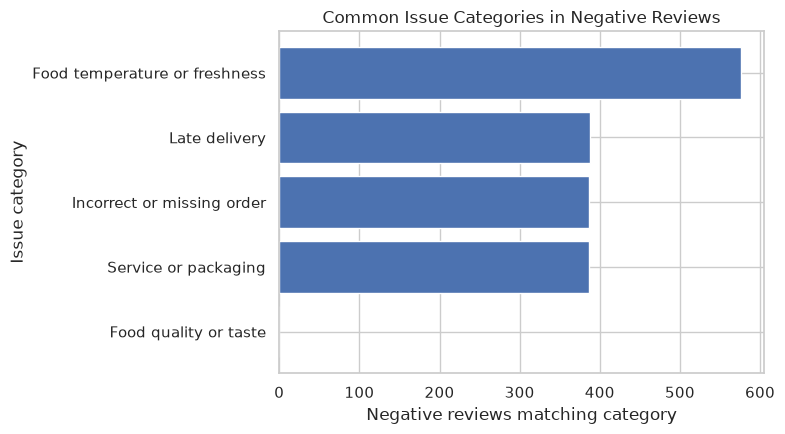

In [18]:
# Visualize the rule-based issue categories.
plot_data = issue_summary.sort_values("negative_reviews_matched")
plt.figure(figsize=(8, 4.5))
plt.barh(plot_data["issue_category"], plot_data["negative_reviews_matched"])
plt.title("Common Issue Categories in Negative Reviews")
plt.xlabel("Negative reviews matching category")
plt.ylabel("Issue category")
plt.tight_layout()
plt.show()

## 10. Compare the model with VADER

VADER is a rule-based sentiment tool designed to handle short, informal text and cues such as punctuation, capitalization, and emoticons. We run it on the original review text, not the stop-word-cleaned text, so these cues are preserved. VADER is an additional comparison, not automatically the better model.

In [19]:
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    vader_available = True
except ImportError:
    vader_available = False
    print("VADER is not installed. In the active .venv, run: python -m pip install vaderSentiment")

In [20]:
if vader_available:
    vader = SentimentIntensityAnalyzer()

    def vader_label(text):
        compound = vader.polarity_scores(str(text))["compound"]
        if compound >= 0.05:
            return "Positive"
        if compound <= -0.05:
            return "Negative"
        return "Neutral"

    reviews["vader_label"] = reviews["review_text"].apply(vader_label)
    vader_accuracy = accuracy_score(reviews["sentiment_label"], reviews["vader_label"])
    vader_report = classification_report(
        reviews["sentiment_label"], reviews["vader_label"],
        output_dict=True, zero_division=0
    )
    vader_report_df = pd.DataFrame(vader_report).transpose()

    print(f"VADER agreement with supplied synthetic labels: {vader_accuracy:.3f}")
    display(reviews["vader_label"].value_counts().rename_axis("vader_sentiment").to_frame("review_count"))
    display(vader_report_df.round(3))

    vader_path = PROCESSED_DIR / "reviews_vader_comparison.csv"
    reviews[["review_text", "sentiment_label", "vader_label"]].to_csv(vader_path, index=False)
    vader_report_path = REPORTS_DIR / "vader_classification_report.csv"
    vader_report_df.to_csv(vader_report_path)
    print("Saved VADER comparison and report.")

VADER agreement with supplied synthetic labels: 0.740


,review_count
vader_sentiment,
Positive,4434
Negative,1343
Neutral,191


,precision,recall,f1-score,support
Negative,0.738,0.838,0.785,1182.00
Neutral,0.000,0.000,0.000,1360.00
Positive,0.773,1.000,0.872,3426.00
accuracy,0.740,0.740,0.740,0.74
macro avg,0.504,0.613,0.552,5968.00
weighted avg,0.590,0.740,0.656,5968.00


Saved VADER comparison and report.


## 11. Save the trained pipeline

The saved scikit-learn pipeline contains both TF-IDF and Naive Bayes. 

In [21]:
model_path = MODEL_DIR / "sentiment_pipeline.joblib"
joblib.dump(sentiment_pipeline, model_path)

# Save a compact metadata file describing the training setup.
metadata = {
    "model": "Multinomial Naive Bayes with TF-IDF",
    "training_records": int(len(X_train)),
    "test_records": int(len(X_test)),
    "text_normalization": LEMMATIZATION_MODE,
    "labels": sorted(y.unique()),
    "random_state": 42
}
metadata_path = MODEL_DIR / "model_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))
print("Saved model:", model_path)
print("Saved metadata:", metadata_path)

Saved model: /home/nineleaps-admin/uber-eats-intelligence/models/day3/sentiment_pipeline.joblib
Saved metadata: /home/nineleaps-admin/uber-eats-intelligence/models/day3/model_metadata.json
